# Lab 4 — Text-to-Image & Latent Space Exploration
**COM SCI-X 455 · Week 4 · Megan Armani, PhD**

> Push to `genai-course/week4/`  |  GPU: T4 or A10G required

---

## Setup

In [1]:
!pip install diffusers transformers accelerate xformers torch --quiet

In [2]:
import torch
from diffusers import (StableDiffusionXLPipeline, DPMSolverMultistepScheduler,
                        StableDiffusionXLControlNetPipeline, ControlNetModel,
                        DDIMScheduler)
from PIL import Image
import numpy as np, matplotlib.pyplot as plt, time

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", DEVICE)
print("VRAM:", torch.cuda.get_device_properties(0).total_memory/1e9, "GB" if DEVICE=='cuda' else "N/A")

    PyTorch 2.10.0+cu128 with CUDA 1208 (you have 2.11.0+cu130)
    Python  3.10.19 (you have 3.13.16)
  Please reinstall xformers (see https://github.com/facebookresearch/xformers#installing-xformers)
  Memory-efficient attention, SwiGLU, sparse and more won't be available.
  Set XFORMERS_MORE_DETAILS=1 for more details


Device: cuda
VRAM: 15.637086208 GB


## Part 1 — SDXL Pipeline + CFG Sweep

In [3]:

import torch
import gc

gc.collect()
torch.cuda.empty_cache()

pipe = StableDiffusionXLPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    torch_dtype=torch.float16,
    use_safetensors=True,
    variant="fp16"
)

pipe.scheduler = DPMSolverMultistepScheduler.from_config(
    pipe.scheduler.config
)

pipe.vae.enable_slicing()
pipe.vae.enable_tiling()

pipe.to("cuda")

print("SDXL loaded successfully!")



/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

SDXL loaded successfully!


In [4]:
!free -h

               total        used        free      shared  buff/cache   available
Mem:            12Gi       3.7Gi       239Mi        12Mi       9.1Gi       9.0Gi
Swap:             0B          0B          0B


  0%|          | 0/20 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:750: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/20 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/20 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/20 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/20 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


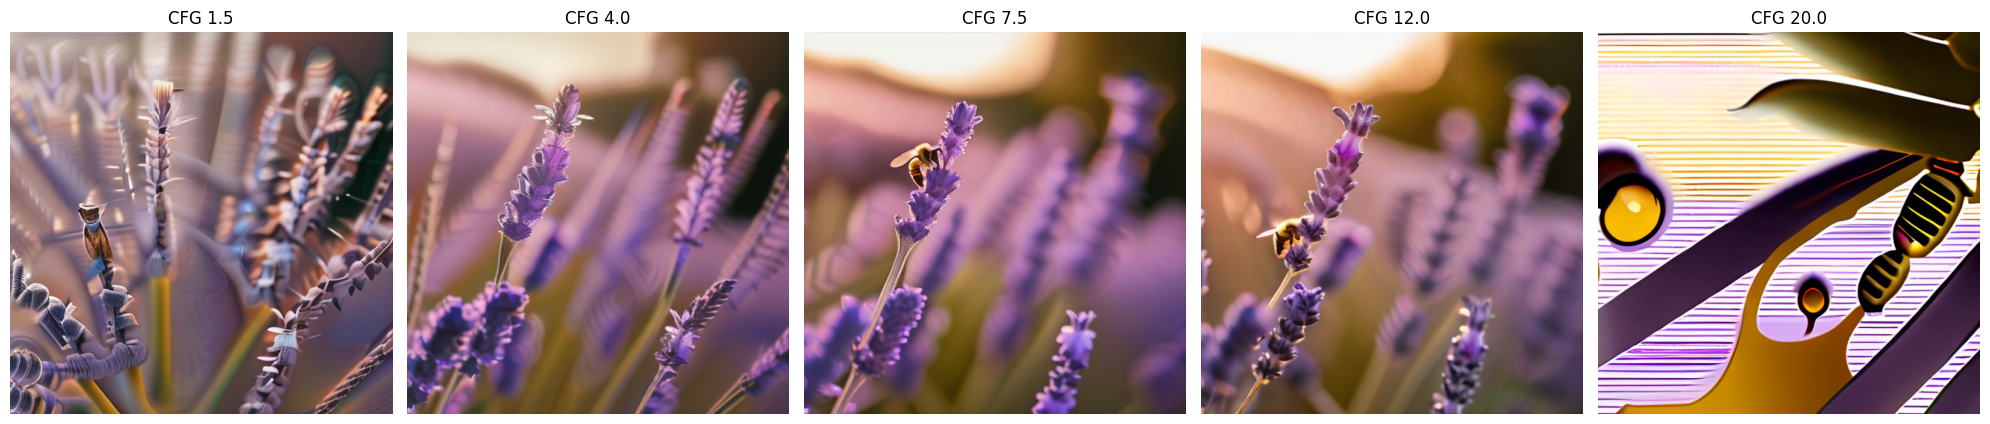

In [5]:
# TODO: Run the same prompt at CFG scales: [1.5, 4.0, 7.5, 12.0, 20.0]
# Use the same seed (torch.Generator('cuda').manual_seed(42)) for each.
# Prompt: 'a photorealistic macro photograph of a honeybee on lavender, golden hour'
# Display all 5 in a 1x5 grid. Label each with its CFG value.
# Note: at what CFG does quality peak? When does it degrade?

# CFG Scale Comparison - SDXL
import torch
import gc
import matplotlib.pyplot as plt

PROMPT = 'a photorealistic macro photograph of a honeybee on lavender, golden hour'
cfg_scales = [1.5, 4.0, 7.5, 12.0, 20.0]

# Enable memory-saving options directly on the VAE
pipe.vae.enable_slicing()
pipe.vae.enable_tiling()

cfg_images = []

for g in cfg_scales:
    gc.collect()
    torch.cuda.empty_cache()

    gen = torch.Generator('cuda').manual_seed(42)

    with torch.inference_mode():
           result = pipe(
           PROMPT,
           guidance_scale=g,
           num_inference_steps=20,
           height=512,
           width=512,
           generator=gen
           )

    cfg_images.append(result.images[0])

    del result, gen
    gc.collect()
    torch.cuda.empty_cache()

# Display all 5 images
fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))

for ax, img, g in zip(axes, cfg_images, cfg_scales):
    ax.imshow(img)
    ax.set_title(f"CFG {g}")
    ax.axis('off')

plt.tight_layout()
fig.savefig('cfg_sweep.png', dpi=150, bbox_inches='tight')
plt.show()


In [6]:
fig.savefig('cfg_sweep.png', dpi=150, bbox_inches='tight')

In [7]:
from google.colab import files
files.download('cfg_sweep.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  0%|          | 0/20 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/20 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


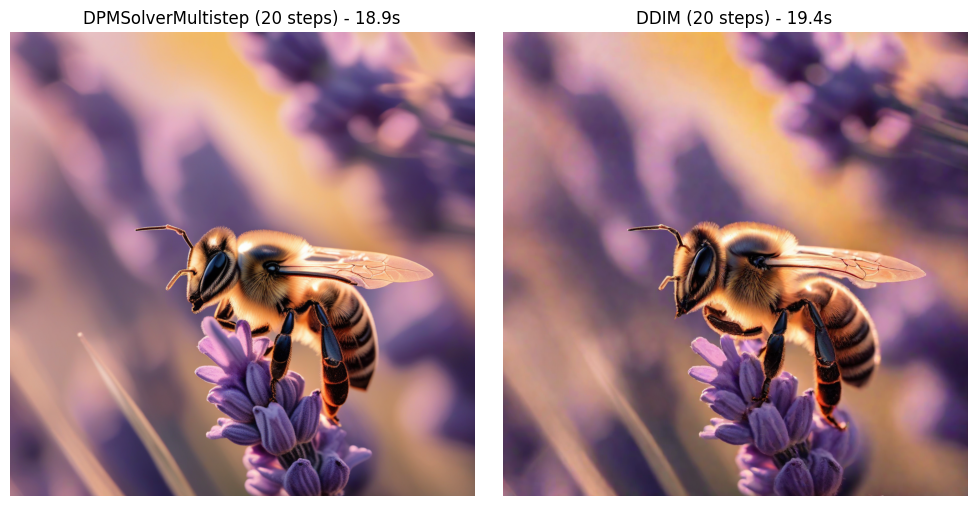

{'DPMSolverMultistep': 18.86, 'DDIM': 19.38}


In [8]:
# TODO: Compare 2 schedulers on the same prompt + seed:
# - DPMSolverMultistepScheduler (20 steps)
# - DDIMScheduler (20 steps)
# Time each. Show outputs side by side. Which is faster? Any quality difference?
import gc

sched_images, sched_times = {}, {}
for name, cls in [("DPMSolverMultistep", DPMSolverMultistepScheduler), ("DDIM", DDIMScheduler)]:
    pipe.scheduler = cls.from_config(pipe.scheduler.config)
    gen = torch.Generator('cuda').manual_seed(42)
    torch.cuda.synchronize(); t0 = time.time()
    sched_images[name] = pipe(PROMPT, num_inference_steps=20, guidance_scale=7.5, generator=gen).images[0]
    torch.cuda.synchronize(); sched_times[name] = time.time() - t0

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (name, img) in zip(axes, sched_images.items()):
    ax.imshow(img); ax.set_title(f"{name} (20 steps) - {sched_times[name]:.1f}s"); ax.axis('off')
plt.tight_layout()
plt.show()
print({k: round(v, 2) for k, v in sched_times.items()})

# free GPU memory before loading the ControlNet pipeline (T4 cannot hold several SDXL copies)
del pipe
gc.collect(); torch.cuda.empty_cache()

## Part 2 — ControlNet Conditioning

In [9]:
import cv2

controlnet = ControlNetModel.from_pretrained(
    "diffusers/controlnet-canny-sdxl-1.0", torch_dtype=torch.float16)
pipe_cn = StableDiffusionXLControlNetPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    controlnet=controlnet, torch_dtype=torch.float16).to(DEVICE)

def get_canny(image_path, low=100, high=200):
    img   = np.array(Image.open(image_path).convert("RGB"))
    edges = cv2.Canny(img, low, high)
    return Image.fromarray(np.stack([edges]*3, axis=-1))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/1.31k [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 5.00GB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Saving Funny_Dog_H.webp to Funny_Dog_H.webp


  0%|          | 0/20 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/controlnet/pipeline_controlnet_sd_xl.py:930: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/20 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/20 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


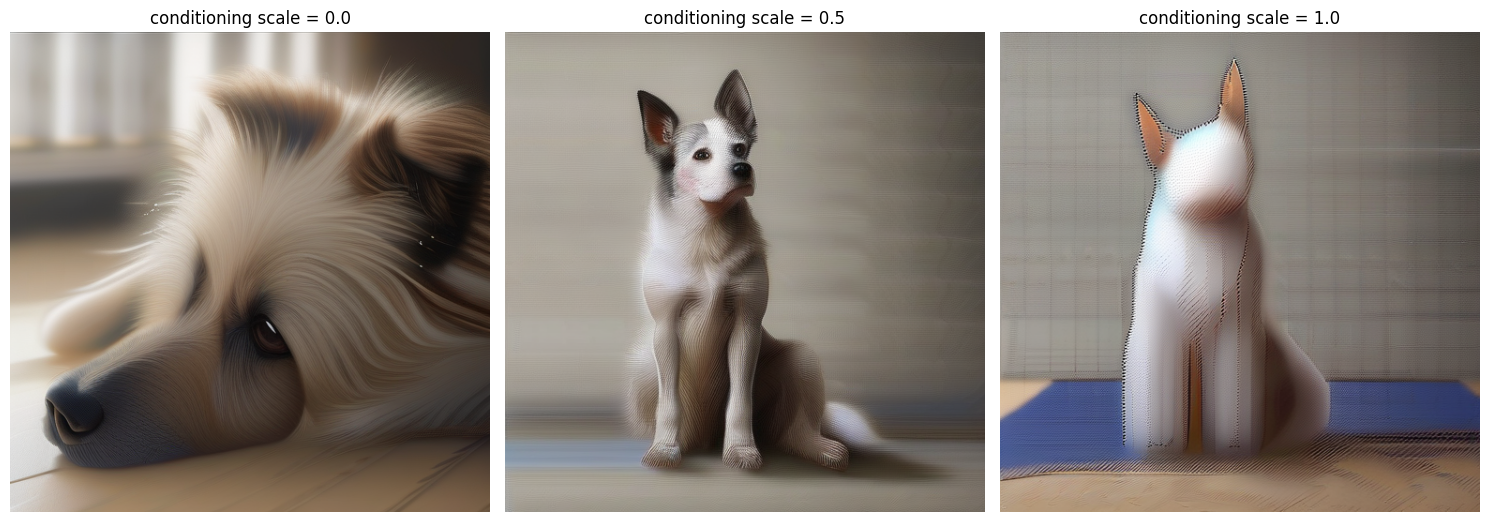

In [10]:
# TODO: Choose any reference image (your own photo or download from Unsplash).
# Extract Canny edges with get_canny().
# Generate the SAME prompt with 3 conditioning scales: [0.0, 0.5, 1.0]
# (0.0 = no conditioning, 1.0 = strict adherence)
# Display as a 1x3 grid. Caption each: does structure help or constrain?
from google.colab import files

uploaded = files.upload()                       # upload your reference image
ref_path = list(uploaded.keys())[0]
canny = get_canny(ref_path).resize((512, 512))

CN_PROMPT = "a photorealistic photograph of a dog, detailed fur, four legs, natural lighting, highly detailed"     # edit to describe your image
cn_scales = [0.0, 0.5, 1.0]

cn_images = []
for s in cn_scales:
    gen = torch.Generator('cuda').manual_seed(42)
    cn_images.append(pipe_cn(CN_PROMPT, image=canny, controlnet_conditioning_scale=s,
                             num_inference_steps=20, generator=gen).images[0])

fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, img, s in zip(axes, cn_images, cn_scales):
    ax.imshow(img); ax.set_title(f"conditioning scale = {s}"); ax.axis('off')
plt.tight_layout()
fig.savefig('controlnet_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

del pipe_cn, controlnet
gc.collect(); torch.cuda.empty_cache()

### 🎯 GitHub Portfolio Callout
Your 1x3 ControlNet comparison = your README header image.
Save it: `fig.savefig('controlnet_comparison.png', dpi=150, bbox_inches='tight')`

In [11]:
fig.savefig('controlnet_comparison.png', dpi=150, bbox_inches='tight')

In [12]:
from google.colab import files
files.download('controlnet_comparison.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Part 3 — Latent Space Interpolation via DDIM Inversion

In [13]:
pipe_ddim = StableDiffusionXLPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    torch_dtype=torch.float16).to(DEVICE)
pipe_ddim.scheduler = DDIMScheduler.from_config(pipe_ddim.scheduler.config)

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


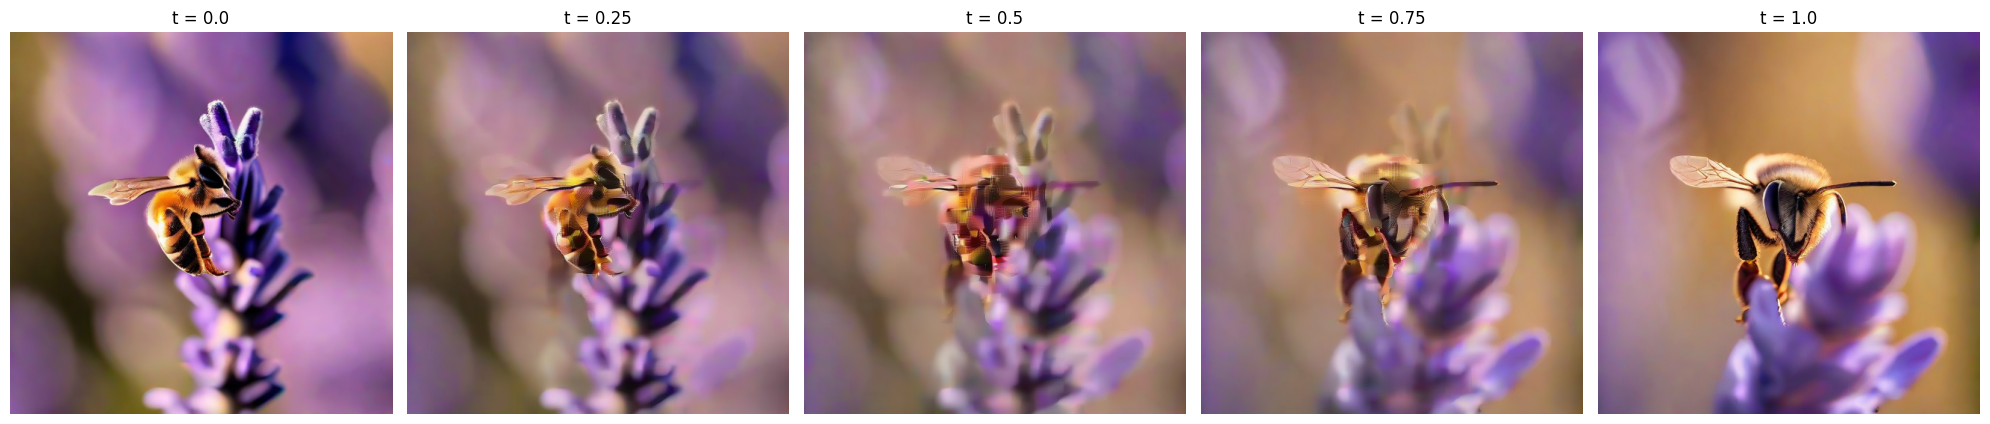

In [14]:
# TODO: Generate 2 images with different seeds (seed=0 and seed=99), same prompt.
# Interpolate between their latents at t=[0.0, 0.25, 0.5, 0.75, 1.0]:
#   z_t = (1-t)*z_A + t*z_B
# Decode each interpolated latent. Show as a 1x5 grid.
# Does the midpoint (t=0.5) look coherent?

import torch
import gc
import matplotlib.pyplot as plt

# Generate latent using a specific seed
def gen_latent(seed):
    gc.collect()
    torch.cuda.empty_cache()

    gen = torch.Generator('cuda').manual_seed(seed)

    with torch.inference_mode():
        result = pipe_ddim(
            PROMPT,
            num_inference_steps=20,
            guidance_scale=7.5,
            height=512,
            width=512,
            generator=gen,
            output_type="latent"
        )

    return result.images.cpu()

# Generate two different latents
z_A = gen_latent(0)
z_B = gen_latent(99)

# Interpolate between them
interp_ts = [0.0, 0.25, 0.5, 0.75, 1.0]
interp_images = []

pipe_ddim.vae.to("cuda", dtype=torch.float32)

for t in interp_ts:
    z = (1 - t) * z_A + t * z_B
    z = z.to("cuda", dtype=torch.float32)

    with torch.inference_mode():
        img = pipe_ddim.vae.decode(
            z / pipe_ddim.vae.config.scaling_factor
        ).sample

    interp_images.append(
        pipe_ddim.image_processor.postprocess(
            img, output_type="pil"
        )[0]
    )

    del z, img
    gc.collect()
    torch.cuda.empty_cache()

# Display results
fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))

for ax, img, t in zip(axes, interp_images, interp_ts):
    ax.imshow(img)
    ax.set_title(f"t = {t}")
    ax.axis("off")

plt.tight_layout()
fig.savefig("latent_interpolation.png", dpi=150, bbox_inches="tight")
plt.show()

# Clean up
del z_A, z_B, interp_images
gc.collect()
torch.cuda.empty_cache()


In [15]:
fig.savefig('latent_interpolation.png', dpi=150, bbox_inches='tight')

In [16]:
from google.colab import files
files.download('latent_interpolation.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### ❓ Reflect
1. At what CFG scale did quality peak for your prompt? Explain mechanistically why high CFG causes oversaturation.
2. ControlNet scale=1.0 constrained creativity. For an e-commerce product catalogue, what scale would you deploy and why?
3. Was the t=0.5 latent interpolation coherent? If not, why does the latent space not produce a clean midpoint?

Reflection

1. Quality was best around CFG 7.5. Lower CFG values gave the AI more freedom, while higher values made it follow the prompt too strongly. Very high CFG can cause oversaturation, making colours too strong and images look unnatural.

2. I would choose a ControlNet scale of around 0.5 for an e-commerce product catalogue. It keeps the product's shape and structure similar to the reference image while still allowing some creativity. This helps make products look consistent without making the images too restricted.

3. The midpoint at t=0.5 was not completely coherent. This is because blending two random latent representations does not always create a meaningful image and the AI may struggle to interpret the mixed information, resulting in unusual or unrealistic details

---
## Submission
- [ ] Push to `genai-course/week4/lab4.ipynb`
- [ ] CFG sweep grid saved
- [ ] ControlNet comparison saved as `controlnet_comparison.png`
- [ ] Latent interpolation grid shown
- [ ] README updated with best images

## Part 4 — CLIP Score Evaluation
**Goal:** Compute CLIP score to measure text-image alignment. Required for Homework Part 3.

In [17]:
!pip install open-clip-torch --quiet
import open_clip, torch
from PIL import Image

clip_model, _, preprocess = open_clip.create_model_and_transforms('ViT-B-32', pretrained='openai')
tokenizer = open_clip.get_tokenizer('ViT-B-32')
clip_model.eval()

def clip_score(image: Image.Image, prompt: str) -> float:
    """Compute cosine similarity between image and text prompt using CLIP."""
    img_tensor  = preprocess(image).unsqueeze(0)
    text_tensor = tokenizer([prompt])
    with torch.no_grad():
        img_feat  = clip_model.encode_image(img_tensor)
        txt_feat  = clip_model.encode_text(text_tensor)
        img_feat /= img_feat.norm(dim=-1, keepdim=True)
        txt_feat /= txt_feat.norm(dim=-1, keepdim=True)
    return (img_feat @ txt_feat.T).item()

print("CLIP scorer ready")

/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


CLIP scorer ready


In [19]:
# TODO: Run clip_score() on your images from Parts 1-3.
# For each image, compute: clip_score(image, original_prompt)
# Build a table: Part | Prompt (first 50 chars) | CLIP Score | Notes
#
# Questions to answer:
# - Does higher CFG correlate with higher CLIP score?
# - Does ControlNet conditioning improve or hurt CLIP score?
# - Which of your 5 generated images has the highest CLIP score?
import pandas as pd

rows = []
for g, img in zip(cfg_scales, cfg_images):
    rows.append(("Part 1 - CFG sweep", f"{PROMPT[:50]} (CFG {g})", clip_score(img, PROMPT)))
for name, img in sched_images.items():
    rows.append(("Part 1 - scheduler", f"{PROMPT[:50]} ({name})", clip_score(img, PROMPT)))
for s, img in zip(cn_scales, cn_images):
    rows.append(("Part 2 - ControlNet", f"{CN_PROMPT[:50]} (scale {s})", clip_score(img, CN_PROMPT)))


table = pd.DataFrame(rows, columns=["Part", "Prompt (first 50 chars)", "CLIP Score"])
table["Notes"] = ""
print(table.round(4).to_string(index=False))

cfg_clip = [r[2] for r in rows[:5]]
print("\nCorrelation between CFG scale and CLIP score:", round(float(np.corrcoef(cfg_scales, cfg_clip)[0, 1]), 3))
print("ControlNet CLIP scores (scale 0.0 / 0.5 / 1.0):", [round(r[2], 4) for r in rows[7:10]])
best = max(rows[:5] + rows[10:], key=lambda r: r[2])
print("Highest CLIP score among the 5 prompt-matched generated images (CFG sweep):", max(zip(cfg_clip, cfg_scales)))
print("Highest overall:", best[0], "|", best[1], "|", round(best[2], 4))

               Part                                                 Prompt (first 50 chars)  CLIP Score Notes
 Part 1 - CFG sweep            a photorealistic macro photograph of a honeybee on (CFG 1.5)      0.2872      
 Part 1 - CFG sweep            a photorealistic macro photograph of a honeybee on (CFG 4.0)      0.3114      
 Part 1 - CFG sweep            a photorealistic macro photograph of a honeybee on (CFG 7.5)      0.3485      
 Part 1 - CFG sweep           a photorealistic macro photograph of a honeybee on (CFG 12.0)      0.3538      
 Part 1 - CFG sweep           a photorealistic macro photograph of a honeybee on (CFG 20.0)      0.2423      
 Part 1 - scheduler a photorealistic macro photograph of a honeybee on (DPMSolverMultistep)      0.3555      
 Part 1 - scheduler               a photorealistic macro photograph of a honeybee on (DDIM)      0.3446      
Part 2 - ControlNet          a photorealistic photograph of a dog, detailed fur (scale 0.0)      0.2799      
Part 2 - C